# Extending the named method registry

A named catalog is a finite map from accepted names to construction rules:

$$
\mathcal R=\{k\mapsto F_k:k\in\mathcal K\},
\qquad x=F_{\pi(a)}(q).
$$

Here, $\mathcal K$ is the set of standard names, $F_k$ is the construction rule stored under name $k$, $a$ is a supplied standard or alternate name, $\pi(a)$ resolves it to a standard name, $q$ contains the supplied settings, and $x$ is the constructed object.

Row,Method family,Available methods,Plain description
,String,Int64,String
1,Bars,6,Methods supplied with the library
2,Cross-validation,6,Methods supplied with the library
3,Feature importance,5,Methods supplied with the library
4,Labels implemented as classes,0,Open extension family
5,Position sizes,0,Open extension family
6,Portfolio methods,0,Open extension family


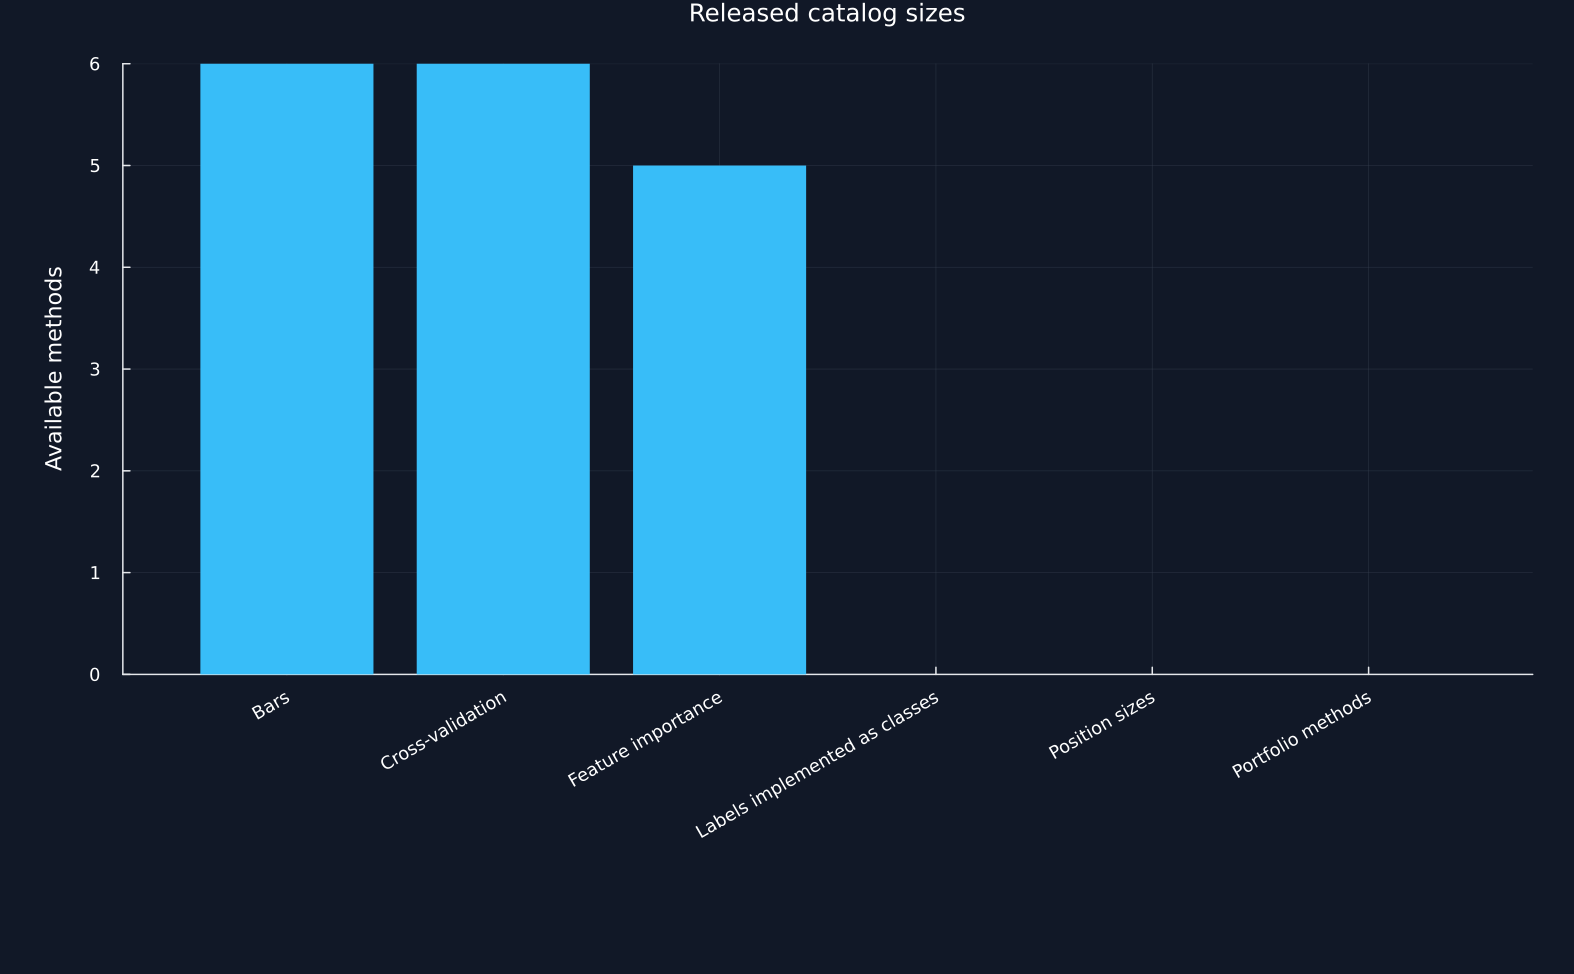

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("32_reproducible_research_study");
using CSV, TOML, Printf
default(left_margin=10Plots.mm,bottom_margin=8Plots.mm)
include(joinpath("..","support","BookHierarchy.jl"))
using .BookHierarchy
using RiskLabAI.Optimization: cluster_variance,hrp,inverse_variance_weights,recursive_bisection
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter21-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
lines = readlines(data_path)
first_row = findfirst(line->startswith(line,",Agric"),lines)
last_row = findnext(line->isempty(strip(line)),lines,first_row+1)
raw = CSV.read(IOBuffer(join(lines[first_row:last_row-1],"\n")),DataFrame)
all_dates = Date.(string.(raw[!,1]),dateformat"yyyymmdd")
all_values = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all(all_values.>-99;dims=2))
dates = all_dates[valid]
selected_assets = names(raw)[2:17]
public_sample = all_values[valid,1:16]/100
annual_covariance,public_correlation = cov(public_sample)*252,cor(public_sample)
using RiskLabAI.ParallelWork
using RiskLabAI.Components
using RiskLabAI.Utils
muted = "#94A3B8"
asset_names = selected_assets
function table(frame,name,caption)
    shown = copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column] = ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter30-"*replace(name,"_"=>"-"))
    return nothing
end
function binance_rows(limit=5000)
    full = load_binance()
    return DataFrame("Date Time"=>full.time[1:limit],"Price"=>full.close[1:limit],"Volume"=>full.volume[1:limit])
end
date_time(value) = Dates.format(value,dateformat"yyyy-mm-dd HH:MM:SS")
function portfolio_weights(method,covariance,correlation)
    method=="Equal weight" && return fill(1/size(covariance,1),size(covariance,1))
    method=="Inverse variance" && return inverse_variance_weights(covariance)
    method=="Hierarchical risk parity" && return hrp(covariance,correlation)
    throw(KeyError(method))
end
function portfolio_record(method,weights,returns)
    daily = returns*weights
    wealth = cumprod(1 .+daily)
    drawdown = wealth./accumulate(max,wealth).-1
    concentration = sum(abs2,weights)
    return (Method=method,Observations=length(daily),annual_mean=mean(daily)*252,annual_volatility=std(daily)*sqrt(252),ratio=mean(daily)/std(daily)*sqrt(252),drawdown=minimum(drawdown),largest=maximum(weights),concentration=concentration,effective=1/concentration)
end
function portfolio_frame(records)
    frame = DataFrame(records)
    rename!(frame,["Method","Observations","Annual mean return","Annual volatility","Return to volatility","Maximum drawdown","Largest weight","Weight concentration","Effective holdings"])
    return sort(frame,["Annual volatility","Method"])
end
catalogue = list_components()
family_order = ["bars","cross_validators","feature_importance","labelers","bet_sizers","portfolio_optimizers"]
family_labels = ["Bars","Cross-validation","Feature importance","Labels implemented as classes","Position sizes","Portfolio methods"]
catalogue_table = DataFrame("Method family"=>family_labels,"Available methods"=>[length(catalogue[name]) for name in family_order],"Plain description"=>[isempty(catalogue[name]) ? "Open extension family" : "Methods supplied with the library" for name in family_order])
table(catalogue_table,"catalogue_counts","Released named method families and their current counts.")
figure = bar(1:6,catalogue_table[!,"Available methods"];color=ifelse.(catalogue_table[!,"Available methods"].>0,palette.cyan,muted),linealpha=0,legend=false,xticks=(1:6,family_labels),xrotation=30,ylabel="Available methods",title="Released catalog sizes",bottom_margin=30Plots.mm,size=(1050,650))
save_figure(figure,paths,"catalogue_counts")


## Sixteen Bar Choices

The controller chooses one construction rule from its accepted name set:

$$
B(a,q)=F_{\pi(a)}(q),
\qquad a\in\mathcal K_{\mathrm{bar}}.
$$

Here, $a$ is an accepted bar name, $\mathcal K_{\mathrm{bar}}$ is the controller's set of sixteen names, $q$ contains the method settings, $\pi$ resolves the name, $F$ is the selected construction rule, and $B(a,q)$ is the resulting bar object.

Row,Order,Bar choice,Family,Constructed class
,Int64,String,String,String
1,1,Expected Dollar Imbalance Bars,Imbalance,Expected imbalance bars
2,2,Expected Volume Imbalance Bars,Imbalance,Expected imbalance bars
3,3,Expected Tick Imbalance Bars,Imbalance,Expected imbalance bars
4,4,Fixed Dollar Imbalance Bars,Imbalance,Fixed imbalance bars
5,5,Fixed Volume Imbalance Bars,Imbalance,Fixed imbalance bars
6,6,Fixed Tick Imbalance Bars,Imbalance,Fixed imbalance bars
7,7,Expected Dollar Run Bars,Run,Expected run bars
8,8,Expected Volume Run Bars,Run,Expected run bars
9,9,Expected Tick Run Bars,Run,Expected run bars


Row,Family,Choices
,String,Int64
1,Imbalance,6
2,Run,6
3,Standard,3
4,Time,1


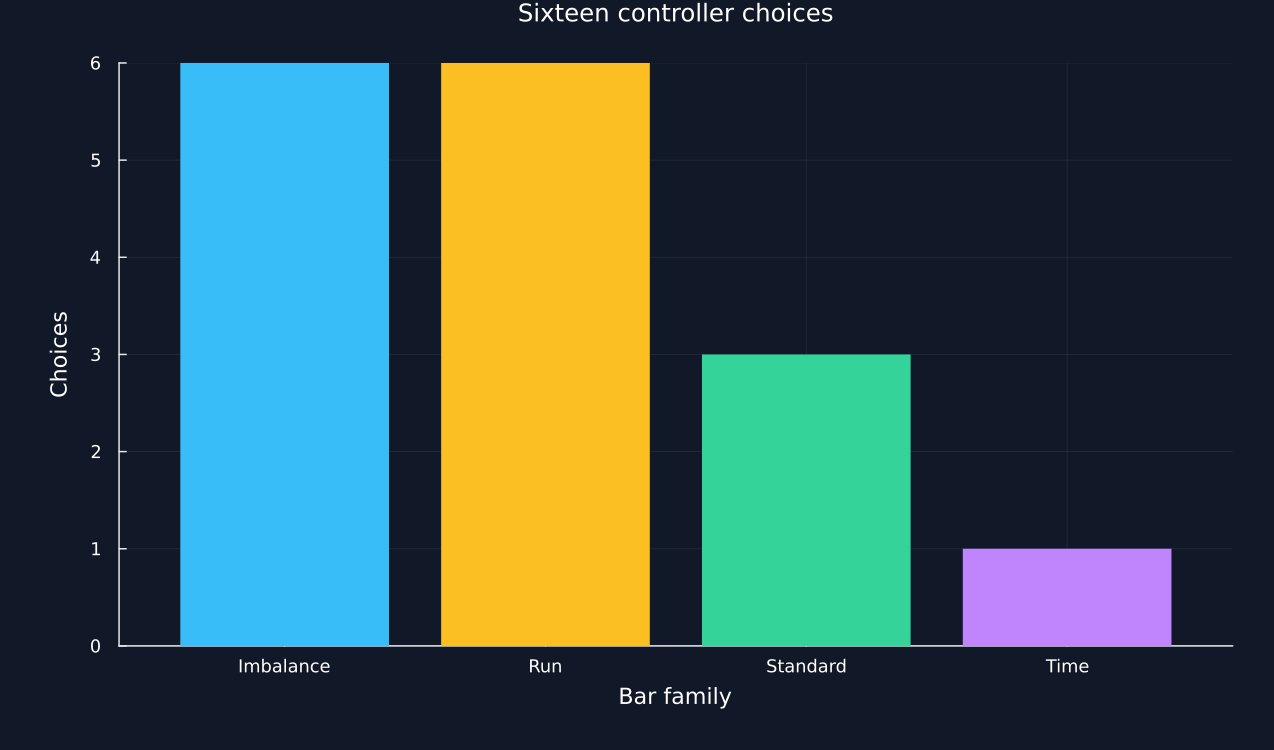

In [2]:
bar_names = bar_methods()
bar_family(name) = occursin("imbalance",name) ? "Imbalance" : occursin("run",name) ? "Run" : occursin("standard",name) ? "Standard" : "Time"
class_labels = Dict(:ExpectedImbalanceBars=>"Expected imbalance bars",:FixedImbalanceBars=>"Fixed imbalance bars",:ExpectedRunBars=>"Expected run bars",:FixedRunBars=>"Fixed run bars",:StandardBars=>"Standard bars",:TimeBars=>"Time bars")
bar_method_table = DataFrame("Order"=>collect(eachindex(bar_names)),"Bar choice"=>titlecase.(replace.(bar_names,"_"=>" ")),"Family"=>bar_family.(bar_names),"Constructed class"=>[class_labels[nameof(typeof(initialize_bars(name)))] for name in bar_names])
family_count_table = combine(groupby(bar_method_table,:Family;sort=true),nrow=>"Choices")
table(bar_method_table,"bar_method_choices","The sixteen controller choices with plain labels.")
table(family_count_table,"bar_family_counts","Counts of controller choices by bar family.")
figure = bar(1:4,family_count_table.Choices;color=[palette.cyan,palette.amber,palette.green,violet],linealpha=0,legend=false,xticks=(1:4,family_count_table.Family),xlabel="Bar family",ylabel="Choices",title="Sixteen controller choices",size=(850,500))
save_figure(figure,paths,"bar_family_counts")


## A New Class Based Label

A fixed horizon label uses the sign of a future return:

$$
\ell_t=\operatorname{sign}\!\left(\frac{P_{t+h}}{P_t}-1\right).
$$

Here, $P_t$ is the price at observation $t$, $h$ is the chosen horizon measured in observations, $P_{t+h}/P_t-1$ is the forward return, and $\ell_t$ is minus one, zero, or one according to its sign.

Row,Stage,Standard name available,Alternate name available
,String,String,String
1,Register,Yes,Yes
2,Create by alternate name,Yes,Yes
3,Reject duplicate,Yes,Yes
4,Remove,No,No


Row,Label,Observations,Meaning
,Int64,Int64,String
1,-1,2431,Lower after three minutes
2,0,3,Equal or unavailable
3,1,2566,Higher after three minutes


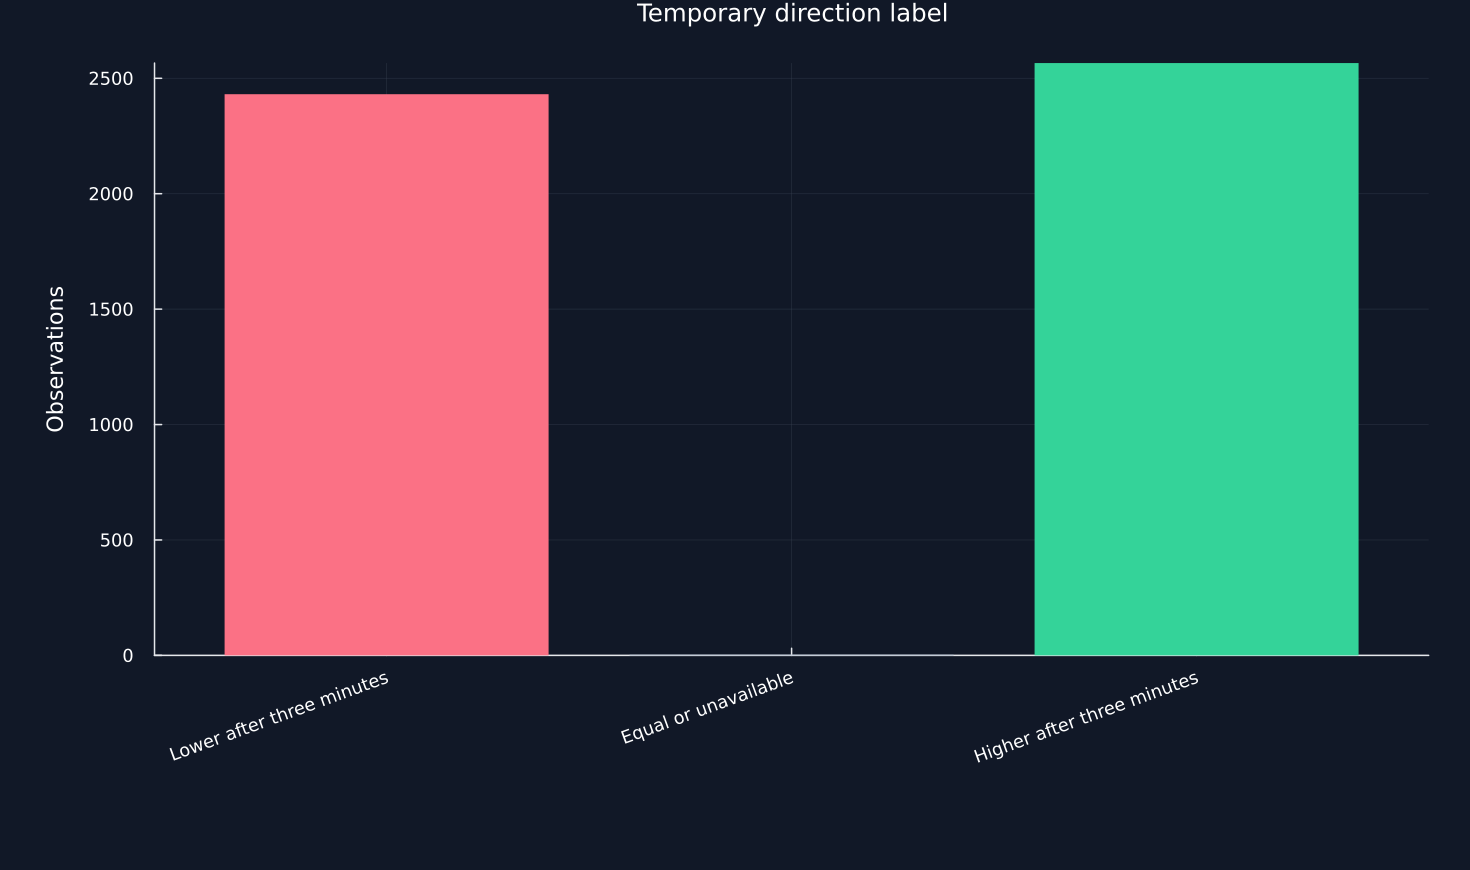

In [3]:
public_ticks = binance_rows(5000)
struct DirectionLabeler <: AbstractLabeler
    horizon::Int
end
DirectionLabeler(;horizon=5) = DirectionLabeler(Int(horizon))
function RiskLabAI.Components.label(model::DirectionLabeler,prices)
    horizon = model.horizon
    forward = vcat(prices[(horizon+1):end]./prices[1:(end-horizon)].-1,fill(NaN,horizon))
    labels = [isnan(value) ? 0 : Int(sign(value)) for value in forward]
    return DataFrame("Direction label"=>labels,"Forward return"=>forward)
end
lifecycle_rows = NamedTuple[]
register_component!(LABELERS,"direction_label",DirectionLabeler;aliases=["future_direction"],metadata=Dict("family"=>"labeling","horizon unit"=>"observations"),accepted_keywords=[:horizon])
push!(lifecycle_rows,(Stage="Register",standard="direction_label" in LABELERS,alternate="future_direction" in LABELERS))
labeler = create_component(LABELERS,"FUTURE_DIRECTION";horizon=3,unused_value=99,filter_unknown_kwargs=true)
labels = label(labeler,public_ticks.Price)
push!(lifecycle_rows,(Stage="Create by alternate name",standard="direction_label" in LABELERS,alternate="future_direction" in LABELERS))
duplicate_blocked = try
    register_component!(LABELERS,"direction_label",DirectionLabeler)
    false
catch failure
    failure isa KeyError || rethrow()
    true
end
push!(lifecycle_rows,(Stage="Reject duplicate",standard=duplicate_blocked,alternate=duplicate_blocked))
label_metadata = component_metadata(LABELERS,"future_direction")
unregister_component!(LABELERS,"direction_label")
push!(lifecycle_rows,(Stage="Remove",standard="direction_label" in LABELERS,alternate="future_direction" in LABELERS))
lifecycle_table = DataFrame(lifecycle_rows)
rename!(lifecycle_table,["Stage","Standard name available","Alternate name available"])
label_summary = DataFrame("Label"=>[-1,0,1],"Observations"=>[count(==(value),labels[!,"Direction label"]) for value in -1:1],"Meaning"=>["Lower after three minutes","Equal or unavailable","Higher after three minutes"])
table(lifecycle_table,"custom_label_lifecycle","Registration, creation, duplicate protection, and removal for a temporary label method.")
table(label_summary,"custom_label_summary","Three-minute direction labels from the public minute records.")
save_data(labels,paths,"all_direction_labels")
figure = bar(1:3,label_summary.Observations;color=[palette.rose,muted,palette.green],linealpha=0,legend=false,xticks=(1:3,label_summary.Meaning),xrotation=20,ylabel="Observations",title="Temporary direction label",bottom_margin=22Plots.mm,size=(980,580))
save_figure(figure,paths,"custom_label_counts")


## Comparing eager construction with delayed construction

A delayed entry changes state only when its construction rule is first requested:

$$
Z_k^{\mathrm{before}}=1,
\qquad Z_k^{\mathrm{after}}=0.
$$

Here, $k$ is the standard name of a catalog entry, $Z_k=1$ means that its construction rule has not yet been resolved, and $Z_k=0$ means that the rule has been loaded after the first request.

In [4]:
struct ScaleValue
    factor::Float64
end
ScaleValue(;factor=1.0) = ScaleValue(Float64(factor))
apply(model::ScaleValue,value) = model.factor*value
temporary_catalog = ComponentRegistry("chapter examples")
register_component!(temporary_catalog,"scale",ScaleValue;aliases=["multiply"],metadata=Dict("family"=>"arithmetic"),accepted_keywords=[:factor])
direct_object = create_component(temporary_catalog,"MULTIPLY";factor=2.5,ignored=10,filter_unknown_kwargs=true)
counter_factory(value) = Dict(character=>count(==(character),value) for character in unique(value))
register_lazy!(temporary_catalog,"counter",()->counter_factory;metadata=Dict("family"=>"counting"))
lazy_before = is_lazy(temporary_catalog,"counter")
counted = create_component(temporary_catalog,"counter","abracadabra")
lazy_after = is_lazy(temporary_catalog,"counter")
registry_check_table = DataFrame("Check"=>["Direct construction","Alternate name","Unknown setting removed","Metadata retained","Delayed before request","Delayed after request","Delayed result"],"Observed result"=>Any[apply(direct_object,4.0),"multiply resolves to scale","Object created",component_metadata(temporary_catalog,"scale")["family"],lazy_before,lazy_after,counted['a']],"Expected result"=>Any[10.0,"multiply resolves to scale","Object created","arithmetic",true,false,5])
table(registry_check_table,"registry_construction_checks","Direct, alternate-name, filtered, metadata, and delayed construction checks.")


Row,Check,Observed result,Expected result
,String,Any,Any
1,Direct construction,10.0,10.0
2,Alternate name,multiply resolves to scale,multiply resolves to scale
3,Unknown setting removed,Object created,Object created
4,Metadata retained,arithmetic,arithmetic
5,Delayed before request,true,true
6,Delayed after request,false,false
7,Delayed result,5,5


## Public Bar Calculation Across Input Batches

A dollar bar ends at the first input row whose accumulated dollar value reaches the threshold:

$$
\tau_k=\inf\left\{n>\tau_{k-1}:\sum_{i=\tau_{k-1}+1}^{n}P_iV_i\geq h_D\right\}.
$$

Here, $k$ labels a completed bar, $\tau_{k-1}$ is the preceding ending row, $n$ is a candidate ending row, $P_i$ and $V_i$ are price and base volume for minute row $i$, $h_D$ is the dollar threshold, and $\inf$ selects the first crossing.

Row,Field,Value
,String,Any
1,Archive,BTCUSDT-1m-2021-01.zip
2,Provider,Binance Data Vision
3,Records used,5000
4,First minute,2021-01-01 00:00:00
5,Last minute,2021-01-04 11:19:00
6,Record meaning,One-minute aggregate


Row,Input grouping,Input rows,Completed bars,Smallest completed dollar value,Last completed time
,String,Int64,Int64,Float64,String
1,One batch,5000,1650,5.00001e6,2021-01-04 11:19:00
2,Seven batches,5000,1650,5.00001e6,2021-01-04 11:19:00


Row,Dollar threshold,Completed bars,Mean rows per bar,Smallest completed dollar value,Mean completed dollar value,Greatest completed dollar value
,Float64,Int64,Float64,Float64,Float64,Float64
1,2.5e6,2590,1.9305,2.50015e6,4.69602e6,4.33476e7
2,5.0e6,1650,3.0303,5.00001e6,7.37133e6,4.33476e7
3,1.0e7,966,5.17598,1.00001e7,1.25908e7,5.2286e7


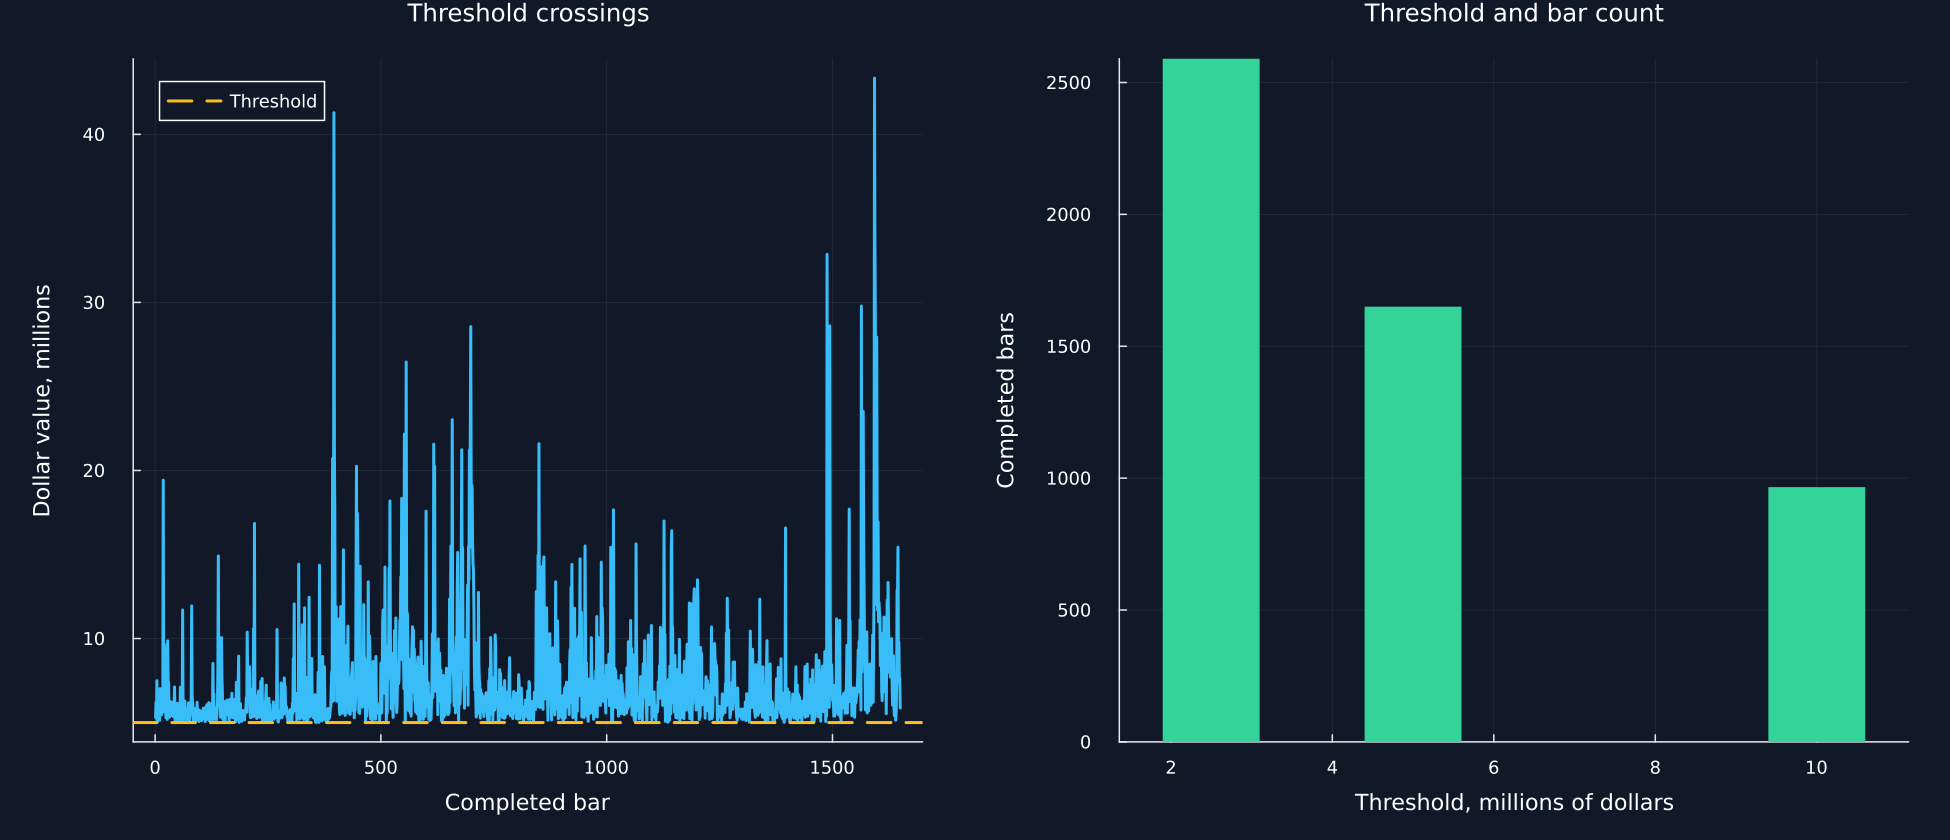

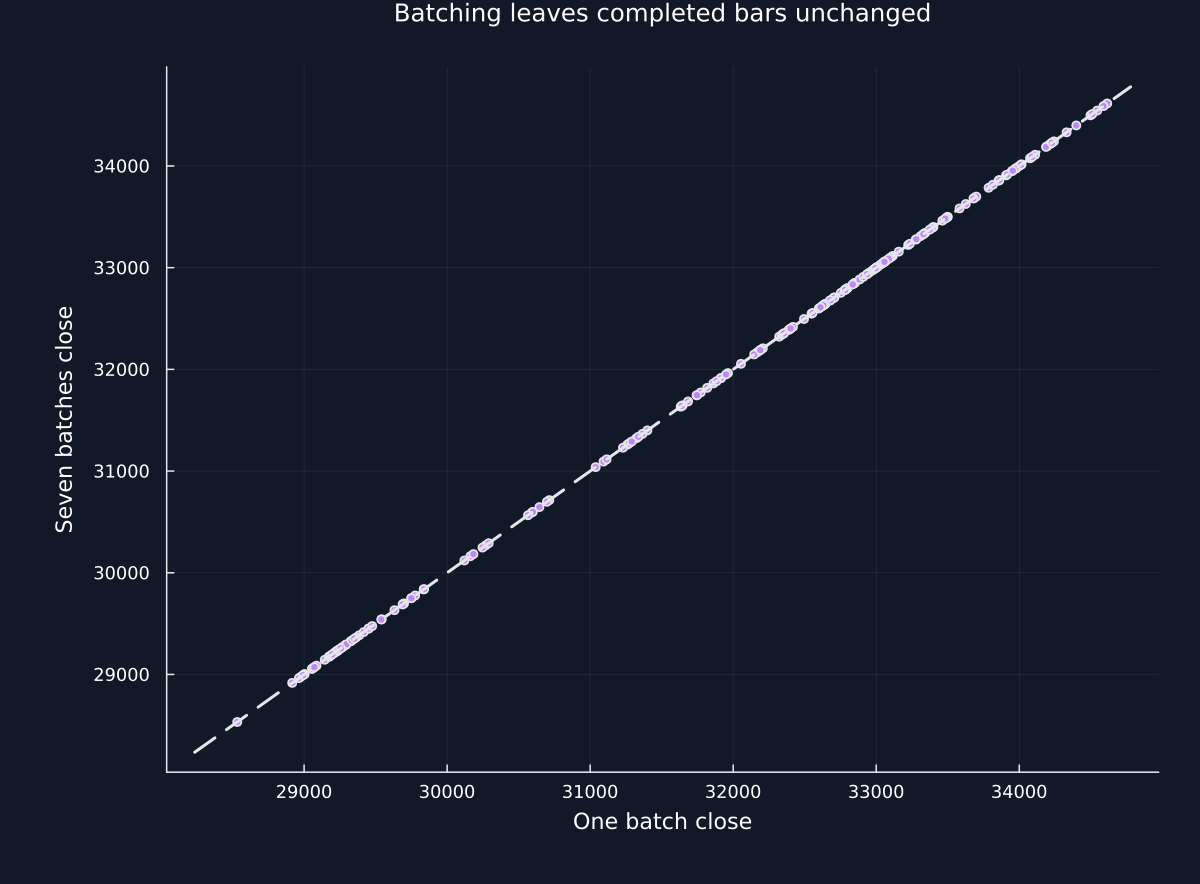

In [5]:
threshold = 5_000_000.0
one_result = process_bars(BarController(),"dollar_standard_bars",(;threshold),public_ticks;batch_size=nrow(public_ticks))
seven_result = process_bars(BarController(),"dollar_standard_bars",(;threshold),public_ticks;batch_size=715)
@assert one_result.completed_input && seven_result.completed_input
@assert one_result.processed_rows==seven_result.processed_rows==5000
one_batch,seven_batches = one_result.bars,seven_result.bars
@assert one_batch==seven_batches
batch_table = DataFrame("Input grouping"=>["One batch","Seven batches"],"Input rows"=>fill(nrow(public_ticks),2),"Completed bars"=>[nrow(one_batch),nrow(seven_batches)],"Smallest completed dollar value"=>[minimum(one_batch[!,CUMULATIVE_DOLLAR]),minimum(seven_batches[!,CUMULATIVE_DOLLAR])],"Last completed time"=>[date_time(maximum(one_batch[!,DATE_TIME])),date_time(maximum(seven_batches[!,DATE_TIME]))])
bar_data_provenance = DataFrame("Field"=>["Archive","Provider","Records used","First minute","Last minute","Record meaning"],"Value"=>Any["BTCUSDT-1m-2021-01.zip","Binance Data Vision",nrow(public_ticks),date_time(first(public_ticks[!,"Date Time"])),date_time(last(public_ticks[!,"Date Time"])),"One-minute aggregate"])
threshold_rows = NamedTuple[]
threshold_outputs = Dict{Float64,DataFrame}()
for selected_threshold in [2_500_000.0,5_000_000.0,10_000_000.0]
    result = process_bars(BarController(),"dollar_standard_bars",(;threshold=selected_threshold),public_ticks;batch_size=715)
    @assert result.completed_input && result.processed_rows==5000
    output = result.bars
    threshold_outputs[selected_threshold] = output
    push!(threshold_rows,(threshold=selected_threshold,bars=nrow(output),rows=nrow(public_ticks)/nrow(output),smallest=minimum(output[!,CUMULATIVE_DOLLAR]),mean=mean(output[!,CUMULATIVE_DOLLAR]),greatest=maximum(output[!,CUMULATIVE_DOLLAR])))
    saved = copy(output)
    saved[!,DATE_TIME] = date_time.(saved[!,DATE_TIME])
    save_data(saved,paths,"bar_rows_"*string(Int(selected_threshold)))
end
threshold_table = DataFrame(threshold_rows)
rename!(threshold_table,["Dollar threshold","Completed bars","Mean rows per bar","Smallest completed dollar value","Mean completed dollar value","Greatest completed dollar value"])
table(bar_data_provenance,"bar_data_provenance","Public minute archive used for the controller checks.")
table(batch_table,"batch_invariance","The same dollar bars from one input batch and seven input batches.")
table(threshold_table,"dollar_threshold_sensitivity","Completed dollar bars at three fixed thresholds.")
p1 = plot(1:nrow(one_batch),one_batch[!,CUMULATIVE_DOLLAR]/1e6;color=palette.cyan,label="",xlabel="Completed bar",ylabel="Dollar value, millions",title="Threshold crossings")
hline!(p1,[threshold/1e6];color=palette.amber,linestyle=:dash,label="Threshold")
p2 = bar(threshold_table[!,1]/1e6,threshold_table[!,2];bar_width=1.2,color=palette.green,linealpha=0,legend=false,xlabel="Threshold, millions of dollars",ylabel="Completed bars",title="Threshold and bar count")
save_figure(plot(p1,p2;layout=(1,2),size=(1300,560)),paths,"dollar_bar_thresholds")
comparison_positions = floor.(Int,range(0,nrow(one_batch)-1;length=min(200,nrow(one_batch)))).+1
figure = scatter(one_batch[comparison_positions,CLOSE_PRICE],seven_batches[comparison_positions,CLOSE_PRICE];color=violet,markersize=3,label="",xlabel="One batch close",ylabel="Seven batches close",title="Batching leaves completed bars unchanged",size=(800,590))
bounds = collect(extrema(one_batch[!,CLOSE_PRICE]))
plot!(figure,bounds,bounds;color=palette.text,linestyle=:dash,label="")
save_figure(figure,paths,"batch_invariance")
save_data(DataFrame("One batch close"=>one_batch[comparison_positions,CLOSE_PRICE],"Seven batches close"=>seven_batches[comparison_positions,CLOSE_PRICE]),paths,"batch_comparison_points")
nothing


## Handling invalid method names

In [6]:
invalid_result = process_bars(BarController(),"unknown bar choice",Dict(),public_ticks;batch_size=715)
invalid_output = invalid_result.bars
invalid_table = DataFrame("Check"=>["Unknown name","Standard output columns","Returned rows","Complete input proved"],"Observed result"=>Any["Rejected",ncol(invalid_output),nrow(invalid_output),"No"])
table(invalid_table,"invalid_controller_check","Controller response to an unknown bar name.")


Row,Check,Observed result
,String,Any
1,Unknown name,Rejected
2,Standard output columns,12
3,Returned rows,0
4,Complete input proved,No


## Tests

In [7]:
@assert [length(catalogue[name]) for name in family_order]==[6,6,5,0,0,0]
@assert length(bar_names)==16
@assert Set(family_count_table.Family)==Set(["Imbalance","Run","Standard","Time"])
@assert size(labels)==(5000,2)
@assert label_metadata==Dict("family"=>"labeling","horizon unit"=>"observations")
@assert duplicate_blocked
@assert !("direction_label" in LABELERS) && !("future_direction" in LABELERS)
@assert apply(direct_object,4.0)==10.0
@assert lazy_before && !lazy_after && counted['a']==5
@assert nrow(one_batch)==nrow(seven_batches)==1650
@assert minimum(one_batch[!,CUMULATIVE_DOLLAR])>=threshold
@assert issorted(threshold_table[!,"Completed bars"];rev=true)
@assert isempty(invalid_output) && names(invalid_output)==BAR_COLUMNS
@assert !invalid_result.completed_input && invalid_result.processed_rows==0 && !isnothing(invalid_result.error)
display(DataFrame("Test"=>["Catalog counts","Sixteen bar names","Four bar families","Custom labels","Metadata","Duplicate protection","Clean removal","Direct construction","Delayed construction","Batch equality","Threshold crossing","Threshold monotonicity","Invalid name"],"Passed"=>fill(true,13)))


Row,Test,Passed
,String,Bool
1,Catalog counts,true
2,Sixteen bar names,true
3,Four bar families,true
4,Custom labels,true
5,Metadata,true
6,Duplicate protection,true
7,Clean removal,true
8,Direct construction,true
9,Delayed construction,true
